# Alternative Topic Discovery under Privacy Group

| Item | Description |
|---|---|
| Goal | Find a small set of recurring subjects within the privacy-assigned records, then show concern and support for each subject. |
| Input | The existing `output/T2.4.3/privacy_and_digital_consumer_protection_stance_turns.csv`, `topic_groups.csv`, and the saved upstream stance records and numbered speech-turn sentences. |
| Output | Four CSVs: model selection, record assignments, a topic summary, and example passages; one settings JSON; coherence and concern/support figures in PNG, SVG, and PDF. All go in `output/T2.4.5/`. |
| Simple method | Compare **4–12** non-negative matrix factorization (NMF) topics using identical TF–IDF features and a fixed seed. Select the highest mean topic coherence; break exact ties in favor of fewer topics. Use that count for all final results. No resampling, LLM calls, or new dependencies. |
| Unit | One original extracted stance record, not a whole speech turn. Reconstruct its cited passage so unrelated parts of a long turn do not become model inputs. |
| Model input | Original topic phrase plus cited passage. The five assigned topic labels, concern/support labels, hearing years, and speaker metadata are not model features. |
| Naming | Labels are the model's leading keywords, generated by a fixed rule. They are not LLM-generated names or a validated taxonomy. |
| Variables | • `n_subthemes`: candidate count, fixed at the selected value for all subsequent outputs.<br>• `mean_npmi`: mean normalized pointwise mutual information across top-term pairs, averaged equally across topics.<br>• `selected`: whether this candidate wins the predefined rule.<br>• `subtheme_id`: the strongest NMF component for a record; 0 means no usable model score.<br>• `subtheme_label`: leading, non-overlapping keywords for that component.<br>• `n_records`, `concern_records`, `support_records`: total and stance-specific record counts.<br>• `n_hearings`, `n_turns`: distinct hearings and speech turns represented in a topic. |
| Sources | • Röder, M., A. Both, and A. Hinneburg (2015). *Exploring the Space of Topic Coherence Measures*. Proceedings of the Eighth ACM International Conference on Web Search and Data Mining, 399–408. [doi:10.1145/2684822.2685324](https://doi.org/10.1145/2684822.2685324). Equation (6), with exponent 1, for NPMI; Section 3.2 for Boolean document probabilities. Here, each record's topic phrase plus cited passage is one document.<br>• [scikit-learn's NMF and TF–IDF topic-modeling example](https://scikit-learn.org/stable/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html). Model settings and installed software versions are saved for replication. |
| Read before interpreting | **All original records are kept**, including potentially off-topic upstream assignments. Inspect the example passages before treating these as privacy categories. A record receives one dominant topic even if it discusses several subjects. Concern about a harm and support for a remedy can be compatible positions. |

**The process is simply:** recover passages → compare 4–12 topics by coherence → fix the selected count → read keywords and examples → compare concern and support.

This is the alternative model-based analysis; see `T2.4.4 - Privacy Topic Stance Volume.ipynb` for the simple comparison of the five original topics. Selection uses text only, never the concern/support contrast. The winning count is best among these candidates under this score, not a claim about the true number of privacy issues. The existing raw-turn CSV and T2.4.1–T2.4.4 figures are not changed.

## Step 1. Import packages

Use the installed analysis packages. There are no external services or model downloads.

In [1]:
import hashlib
import json
import platform
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from matplotlib.ticker import MaxNLocator
from matplotlib.transforms import blended_transform_factory
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from threadpoolctl import threadpool_limits
from IPython.display import Image, Markdown, display

## Step 2. Choose files and candidate counts

Compare 4–12 topics with the same seed and ten leading terms per topic. Keep these choices fixed before inspecting scores or stance counts.

In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SOURCE_DATA_FOLDER = Path("/project2/mmiric_1435/acroh/llm_method/data")
NOTEBOOK_FOLDER = PROJECT_FOLDER / "T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection"
OUTPUT_ROOT = NOTEBOOK_FOLDER / "output"
OUTPUT_FOLDER = OUTPUT_ROOT / "T2.4.5"
SAMPLE_FILE = OUTPUT_ROOT / "T2.4.3" / "privacy_and_digital_consumer_protection_stance_turns.csv"
GROUPS_FILE = NOTEBOOK_FOLDER / "topic_groups.csv"
RECORDS_FILE = SOURCE_DATA_FOLDER / "interim/topics/taxonomy/track2_assigned.parquet"
TURNS_FILE = SOURCE_DATA_FOLDER / "interim/topics/track2/member_turns.parquet"

TARGET_GROUP = "Privacy and digital consumer protection"
CANDIDATE_SUBTHEMES = list(range(4, 13))
RANDOM_SEED = 1089
N_TOP_TERMS = 10
N_LABEL_TERMS = 3
N_REPRESENTATIVE_EXAMPLES = 2
N_RANDOM_EXAMPLES = 1
TURN_KEYS = ["packageId", "turn_idx"]
RECORD_KEYS = TURN_KEYS + ["record_idx"]
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Candidate counts: {CANDIDATE_SUBTHEMES}; seed: {RANDOM_SEED}")
print(f"scikit-learn: {sklearn.__version__}; outputs: {OUTPUT_FOLDER}")

Candidate counts: [4, 5, 6, 7, 8, 9, 10, 11, 12]; seed: 1089
scikit-learn: 1.9.0; outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.5


## Step 3. Apply the figure style

Use the shared 9-by-6-inch canvas, serif font, and prescribed concern/support colors. Use the same table-column layout as T2.4.4 for the stance chart. Bold headers use DejaVu Serif because Times New Roman has no installed bold face. The title and note remain outside the exported image.

In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3
EXPORT_DPI = 300
BOLD_TEXT = {"fontweight": "bold", "fontfamily": "DejaVu Serif"}

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 9
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

## Step 4. Read the existing speech-turn sample

Use the previously exported turns to define the sample. Do not change its rows or its concern/support labels.

In [4]:
sample_columns = TURN_KEYS + [
    "chamber", "hearing_year", "heldDate_first", "bioGuideId", "legislator",
    "has_concern", "has_support", "n_stance_records",
]
sample_turns = pd.read_csv(SAMPLE_FILE, usecols=sample_columns)
assert not sample_turns.duplicated(TURN_KEYS).any()
assert sample_turns["hearing_year"].between(1999, 2025).all()
assert sample_turns["n_stance_records"].gt(0).all()
print(f"Speech turns: {len(sample_turns):,}; hearings: {sample_turns['packageId'].nunique():,}")
display(sample_turns.head(3))

Speech turns: 1,086; hearings: 551


,packageId,chamber,hearing_year,heldDate_first,turn_idx,bioGuideId,legislator,has_concern,has_support,n_stance_records
0,CHRG-106shrg69592,SENATE,1999,1999-05-26,17,0000000,The Chairman,True,False,1
1,CHRG-106shrg69985,SENATE,1999,1999-05-27,4,W000779,Senator Wyden,False,True,3
2,CHRG-106shrg69984,SENATE,1999,1999-06-10,1,B001126,Senator Burns,False,True,2


## Step 5. Recover the individual stance records

The turn-level CSV bundles several records together. Recover the original records for this group, matching the CSV's record count for every turn.

In [5]:
topic_groups = pd.read_csv(GROUPS_FILE)
assert topic_groups["topic_id"].is_unique
selected_topics = topic_groups.loc[topic_groups["group"].eq(TARGET_GROUP)]
assert not selected_topics.empty
records = pd.read_parquet(
    RECORDS_FILE,
    columns=RECORD_KEYS + ["topic_id", "topic_label", "topic", "stance", "sentences", "bioGuideId"],
    filters=[("topic_id", "in", selected_topics["topic_id"].tolist())],
)
records = records.rename(columns={"sentences": "sentence_ids", "bioGuideId": "record_bioGuideId"})
records = records.merge(sample_turns, on=TURN_KEYS, how="inner", validate="many_to_one")
assert not records.duplicated(RECORD_KEYS).any()
assert records["stance"].isin(["concern", "support"]).all()
assert records["topic"].notna().all()
assert records["record_bioGuideId"].eq(records["bioGuideId"]).all()
pd.testing.assert_series_equal(
    records.groupby(TURN_KEYS).size().sort_index(),
    sample_turns.set_index(TURN_KEYS)["n_stance_records"].sort_index(),
    check_names=False,
)
records = records.sort_values(RECORD_KEYS).reset_index(drop=True)
print(f"Selected topics: {len(selected_topics)}; individual stance records: {len(records):,}")
display(records[RECORD_KEYS + ["topic", "stance"]].head(3))

Selected topics: 5; individual stance records: 1,654


,packageId,turn_idx,record_idx,topic,stance
0,CHRG-106shrg69592,17,1,pro-competitive multi-channel video policies,concern
1,CHRG-106shrg69984,1,1,strong encryption,support
2,CHRG-106shrg69984,1,3,encryption,support


## Step 6. Recover each record's cited passage

Use the original one-based sentence numbers. This preserves the exact evidence for each position instead of using the entire speech turn.

In [6]:
member_turns = pd.read_parquet(
    TURNS_FILE, columns=TURN_KEYS + ["bioGuideId", "sentences"],
    filters=[("packageId", "in", sample_turns["packageId"].unique().tolist())],
)
member_turns = member_turns.rename(
    columns={"sentences": "turn_sentences", "bioGuideId": "turn_bioGuideId"}
)
records = records.merge(member_turns, on=TURN_KEYS, how="left", validate="many_to_one")
assert records["turn_sentences"].notna().all()
assert records["bioGuideId"].eq(records["turn_bioGuideId"]).all()
cited_passages = []
sentence_lists = []
for row in records.itertuples(index=False):
    sentence_ids = [int(number) for number in row.sentence_ids]
    assert sentence_ids and min(sentence_ids) >= 1
    assert max(sentence_ids) <= len(row.turn_sentences)
    cited_sentences = [row.turn_sentences[number - 1] for number in sentence_ids]
    cited_passages.append(" ".join(cited_sentences))
    sentence_lists.append(json.dumps(sentence_ids))
records["cited_text"] = cited_passages
records["sentence_ids"] = sentence_lists
records = records.drop(columns=["turn_sentences", "turn_bioGuideId", "record_bioGuideId"])
assert records["cited_text"].str.strip().ne("").all()
print(f"Verified passages: {len(records):,}")
display(records[["topic", "stance", "cited_text"]].head(3))

Verified passages: 1,654


,topic,stance,cited_text
0,pro-competitive multi-channel video policies,concern,"Of course, the pro-competitive multi-channel v..."
1,strong encryption,support,Strong encryption is necessary if we are to pr...
2,encryption,support,The solution to this problem is to let individ...


## Step 7. Convert the passages into word features

TF–IDF gives more weight to distinctive words and two-word phrases. Remove common English words, conversational filler, procedural terms, and obvious stance cues using the explicit list below. Do not remove any records.

In [7]:
extra_stopwords = [
    "mr", "mrs", "ms", "senator", "chairman", "chairwoman", "committee",
    "thank", "thanks", "today", "hearing", "witness", "witnesses",
    "think", "going", "just", "people", "want", "make", "know", "like", "sure",
    "say", "said", "saying", "tell", "told", "ask", "asked", "question", "questions",
    "answer", "answers", "talk", "talking", "let", "really", "got",
    "ve", "don", "doesn", "didn", "isn", "wasn", "aren", "hasn", "haven",
    "wouldn", "couldn", "shouldn", "won", "ll", "re",
    "support", "supports", "supported", "supporting",
    "concern", "concerns", "concerned", "concerning",
]
stopwords = sorted(set(ENGLISH_STOP_WORDS).union(extra_stopwords))
records["model_text"] = records["topic"] + ". " + records["cited_text"]
vectorizer = TfidfVectorizer(
    lowercase=True, stop_words=stopwords, ngram_range=(1, 2),
    min_df=3, max_df=0.9, sublinear_tf=True,
    token_pattern=r"(?u)\b[a-z][a-z]+\b",
)
word_matrix = vectorizer.fit_transform(records["model_text"])
feature_names = vectorizer.get_feature_names_out()
has_features = word_matrix.getnnz(axis=1) > 0
assert word_matrix.shape[1] >= max(max(CANDIDATE_SUBTHEMES), N_TOP_TERMS)
assert has_features.sum() >= max(CANDIDATE_SUBTHEMES)
print(f"Records: {word_matrix.shape[0]:,}; word features: {word_matrix.shape[1]:,}")
print(f"Records with no retained words: {(~has_features).sum():,}")

Records: 1,654; word features: 2,468
Records with no retained words: 3


## Step 8. Measure how well the keywords fit together

For each topic, take the same ten leading terms, including two-word phrases. NPMI compares how often each pair appears together with how often it would co-occur by chance. Average the 45 pair scores, then average equally across topics. Count term presence in the same record-level model texts used above; repeated occurrences within one record count once.

Use the unsmoothed formula: $\log[p(a,b)/(p(a)p(b))]/[-\log p(a,b)]$. A pair that never co-occurs scores −1; a pair present in every document is assigned 1. This is an in-sample coherence comparison, not external validation or a stability test. Overlapping words and phrases can raise coherence, so examples still need review.

In [8]:
def mean_topic_coherence(components, term_presence, n_top_terms):
    topic_scores = []
    for component in components:
        top_indices = component.argsort()[::-1][:n_top_terms]
        top_presence = term_presence[:, top_indices]
        term_probabilities = np.asarray(top_presence.mean(axis=0)).ravel()
        pair_probabilities = (top_presence.T @ top_presence).toarray() / term_presence.shape[0]
        left_indices, right_indices = np.triu_indices(n_top_terms, k=1)
        joint = pair_probabilities[left_indices, right_indices]
        independent = term_probabilities[left_indices] * term_probabilities[right_indices]
        pair_scores = np.full(joint.shape, -1.0)
        observed = (joint > 0) & (joint < 1)
        pair_scores[joint == 1] = 1.0
        pair_scores[observed] = np.log(joint[observed] / independent[observed]) / -np.log(joint[observed])
        topic_scores.append(pair_scores.mean())
    return float(np.mean(topic_scores))

word_presence = word_matrix.copy()
word_presence.data[:] = 1.0

## Step 9. Select the number using a fixed rule

Fit each candidate on identical text features with identical settings. Choose the highest mean NPMI using the full, unrounded score. If scores tie exactly, choose fewer topics. Keep the selected count in N_SUBTHEMES for every subsequent output; concern/support labels do not enter this decision.

In [9]:
candidate_scores = []
for candidate_count in CANDIDATE_SUBTHEMES:
    candidate_model = NMF(
        n_components=candidate_count, init="nndsvda", random_state=RANDOM_SEED,
        max_iter=1000, tol=0.0001,
    )
    with threadpool_limits(limits=1):
        candidate_model.fit(word_matrix)
    assert candidate_model.n_iter_ < candidate_model.max_iter, f"Candidate {candidate_count} did not converge."
    coherence = mean_topic_coherence(candidate_model.components_, word_presence, N_TOP_TERMS)
    assert np.isfinite(coherence) and -1 <= coherence <= 1
    candidate_scores.append({
        "n_subthemes": candidate_count, "mean_npmi": coherence,
        "n_iterations": candidate_model.n_iter_,
    })
model_selection = pd.DataFrame(candidate_scores)
ranked_models = model_selection.sort_values(["mean_npmi", "n_subthemes"], ascending=[False, True])
best_model_row = ranked_models.iloc[0]
N_SUBTHEMES = int(best_model_row["n_subthemes"])
model_selection["selected"] = model_selection["n_subthemes"].eq(N_SUBTHEMES)
display(model_selection)
print(f"Selected count: {N_SUBTHEMES}; mean NPMI: {best_model_row['mean_npmi']:.6f}.")
print("Best among the tested counts under this criterion, not an estimate of the true number of issues.")

,n_subthemes,mean_npmi,n_iterations,selected
0,4,0.218649,74,True
1,5,0.184129,98,False
2,6,0.170161,129,False
3,7,0.113165,157,False
4,8,0.153557,417,False
5,9,0.138924,96,False
6,10,0.098772,231,False
7,11,0.058601,265,False
8,12,0.006382,495,False


Selected count: 4; mean NPMI: 0.218649.
Best among the tested counts under this criterion, not an estimate of the true number of issues.


## Step 10. Show the comparison

Plot every candidate's mean coherence and mark the selected count. Keep the candidate range and scoring rule unchanged after seeing the results.

**Figure 1. Coherence by Number of Topics under Privacy Group**

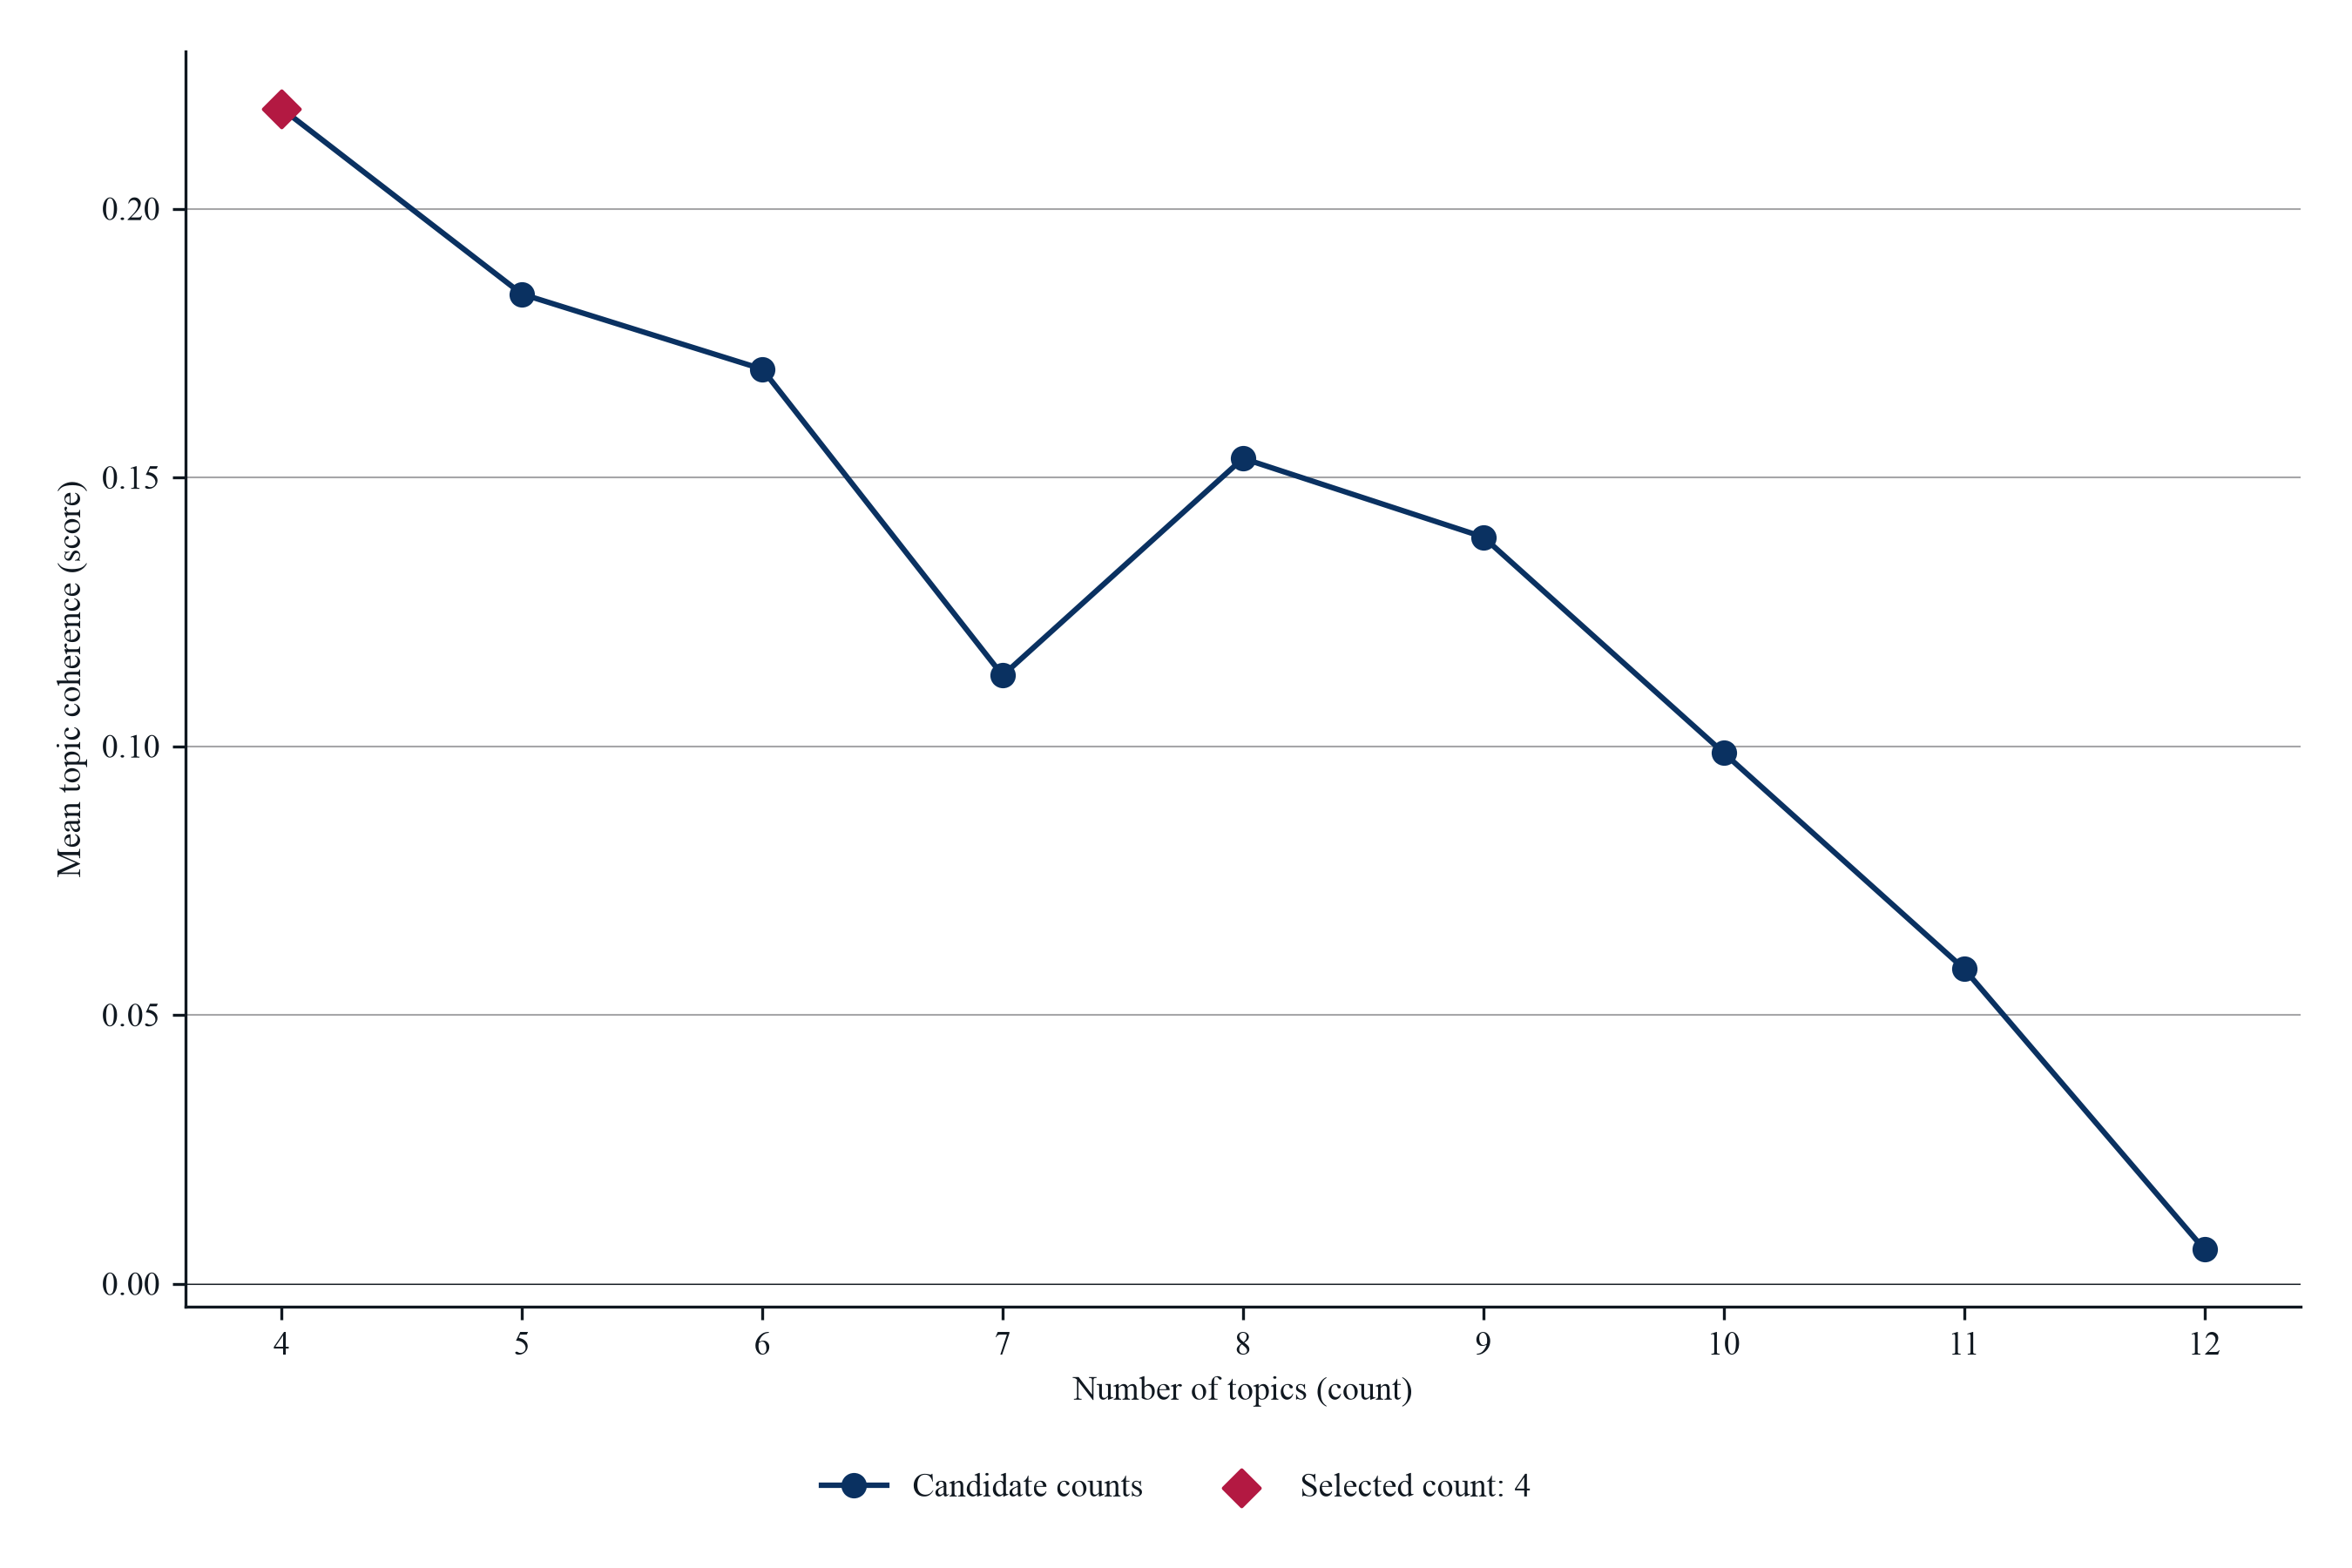

*Notes*: 1,654 privacy-group stance records. Compare 4–12 topics using identical features and seed 1089. Coherence averages normalized pointwise mutual information across each topic's top 10 term pairs, then equally across topics. Selected: 4, by highest score; exact ties favor fewer topics. Selection does not use concern/support labels.

*Source*: Saved stance texts; NMF and document-level NPMI.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.5/fig_privacy_subtheme_coherence


In [10]:
figure_name = "fig_privacy_subtheme_coherence"
figure_title = "Figure 1. Coherence by Number of Topics under Privacy Group"
figure, axis = plt.subplots()
figure.subplots_adjust(
    left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH,
    top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.2,
)
axis.plot(model_selection["n_subthemes"], model_selection["mean_npmi"],
          color=BLUE, marker="o", label="Candidate counts")
axis.scatter(N_SUBTHEMES, best_model_row["mean_npmi"], color=RED,
             marker="D", s=50, zorder=3, label=f"Selected count: {N_SUBTHEMES}")
axis.set_xticks(CANDIDATE_SUBTHEMES)
axis.set_xlabel("Number of topics (count)")
axis.set_ylabel("Mean topic coherence (score)")
axis.spines[["top", "right"]].set_visible(False)
if axis.get_ylim()[0] <= 0 <= axis.get_ylim()[1]:
    axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH)
legend = figure.legend(
    loc="lower center", bbox_to_anchor=(0.5, MARGIN_INCHES / FIGURE_HEIGHT),
    bbox_transform=figure.transFigure, ncol=2, frameon=False, borderaxespad=0,
)
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
leftmost_label = axis.yaxis.label.get_window_extent(renderer).x0
left_shift = (MARGIN_INCHES * figure.dpi - leftmost_label) / figure.bbox.width
legend_top = legend.get_window_extent(renderer).y1
label_bottom = axis.xaxis.label.get_window_extent(renderer).y0
bottom_shift = (legend_top + MARGIN_INCHES * figure.dpi - label_bottom) / figure.bbox.height
figure.subplots_adjust(
    left=figure.subplotpars.left + left_shift,
    bottom=figure.subplotpars.bottom + bottom_shift,
)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
figure_notes = (
    f"{len(records):,} privacy-group stance records. Compare {min(CANDIDATE_SUBTHEMES)}–"
    f"{max(CANDIDATE_SUBTHEMES)} topics using identical features and seed {RANDOM_SEED}. "
    f"Coherence averages normalized pointwise mutual information across each topic's "
    f"top {N_TOP_TERMS} term pairs, then equally across topics. "
    f"Selected: {N_SUBTHEMES}, by highest score; exact ties favor fewer topics. "
    "Selection does not use concern/support labels."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: Saved stance texts; NMF and document-level NPMI."))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")

## Step 11. Use the selected number of topics

Fit the final model with the selected count and identical settings. Verify its coherence matches the comparison. Assign each record to its largest component contribution, adjusting component sizes so weights are comparable. Zero-score records stay unassigned; a dominant assignment simplifies mixed passages.

In [11]:
model = NMF(
    n_components=N_SUBTHEMES, init="nndsvda", random_state=RANDOM_SEED,
    max_iter=1000, tol=0.0001,
)
with threadpool_limits(limits=1):
    record_weights = model.fit_transform(word_matrix)
assert model.n_iter_ < model.max_iter, "NMF did not converge; do not interpret this run."
final_coherence = mean_topic_coherence(model.components_, word_presence, N_TOP_TERMS)
assert np.isclose(final_coherence, best_model_row["mean_npmi"], rtol=0, atol=1e-12)
component_sizes = np.linalg.norm(model.components_, axis=1)
contributions = record_weights * component_sizes
has_assignment = contributions.sum(axis=1) > 0
records["subtheme_id"] = contributions.argmax(axis=1) + 1
records.loc[~has_assignment, "subtheme_id"] = 0
records["subtheme_weight"] = contributions.max(axis=1)
print(f"Final model: {N_SUBTHEMES} topics, fitted in {model.n_iter_} iterations.")
print(f"Assigned records: {has_assignment.sum():,}; unassigned: {(~has_assignment).sum():,}")

Final model: 4 topics, fitted in 74 iterations.
Assigned records: 1,651; unassigned: 3


## Step 12. Name topics with their keywords

Use the highest-weighted terms, skipping repeated words in the short label. These reproducible keyword labels are placeholders for human interpretation, not another clustering step.

In [12]:
subtheme_rows = []
for component_index, component in enumerate(model.components_):
    top_indices = component.argsort()[::-1][:N_TOP_TERMS]
    top_terms = feature_names[top_indices].tolist()
    label_terms = []
    used_words = set()
    for term in top_terms:
        if not used_words.intersection(term.split()):
            label_terms.append(term)
            used_words.update(term.split())
        if len(label_terms) == N_LABEL_TERMS:
            break
    subtheme_rows.append({
        "subtheme_id": component_index + 1,
        "subtheme_label": " / ".join(label_terms),
        "top_terms": "; ".join(top_terms),
    })
subthemes = pd.DataFrame(subtheme_rows)
label_lookup = subthemes.set_index("subtheme_id")["subtheme_label"].to_dict()
label_lookup[0] = "Unassigned"
records["subtheme_label"] = records["subtheme_id"].map(label_lookup)
display(subthemes)

,subtheme_id,subtheme_label,top_terms
0,1,privacy / legislation / federal,privacy; legislation; privacy legislation; fed...
1,2,children / facebook / media,children; facebook; media; kids; social; socia...
2,3,data / security / information,data; security; data privacy; data security; i...
3,4,online / act / protection,online; act; online privacy; protection; priva...


## Step 13. Count concern and support within topics

Attach the original stance labels only for summarizing the fitted topics. Each record counts once. Distinct hearings and turns may appear in several topics.

In [13]:
summary = pd.crosstab(records["subtheme_id"], records["stance"])
summary = summary.reindex(columns=["concern", "support"], fill_value=0)
summary = summary.rename(columns={"concern": "concern_records", "support": "support_records"})
summary.columns.name = None
summary["n_records"] = summary["concern_records"] + summary["support_records"]
summary["n_hearings"] = records.groupby("subtheme_id")["packageId"].nunique()
distinct_turns = records.drop_duplicates(["subtheme_id"] + TURN_KEYS)
summary["n_turns"] = distinct_turns.groupby("subtheme_id").size()
summary = summary.reset_index().merge(subthemes, on="subtheme_id", how="left", validate="one_to_one")
summary.loc[summary["subtheme_id"].eq(0), "subtheme_label"] = "Unassigned"
summary["top_terms"] = summary["top_terms"].fillna("")
summary = summary.sort_values(["n_records", "subtheme_id"], ascending=[False, True]).reset_index(drop=True)
assert summary["n_records"].sum() == len(records)
assert summary["concern_records"].sum() == records["stance"].eq("concern").sum()
assert summary["support_records"].sum() == records["stance"].eq("support").sum()
print(f"Topic summary rows: {len(summary)}")
display(summary)

Topic summary rows: 5


,subtheme_id,concern_records,support_records,n_records,n_hearings,n_turns,subtheme_label,top_terms
0,2,646,266,912,407,672,children / facebook / media,children; facebook; media; kids; social; socia...
1,1,134,169,303,132,224,privacy / legislation / federal,privacy; legislation; privacy legislation; fed...
2,3,144,121,265,149,206,data / security / information,data; security; data privacy; data security; i...
3,4,69,102,171,85,134,online / act / protection,online; act; online privacy; protection; priva...
4,0,3,0,3,3,3,Unassigned,


## Step 14. Prepare example passages for review

For each topic and stance, show two strongly weighted records and one randomly sampled remaining record. Inspect these passages for meaning and off-topic upstream assignments. No relevance filter or record exclusions are applied.

In [14]:
example_groups = []
for group_key, group_records in records.groupby(["subtheme_id", "stance"], sort=True):
    ordered_records = group_records.sort_values(
        ["subtheme_weight"] + RECORD_KEYS, ascending=[False, True, True, True]
    )
    representative = ordered_records.head(N_REPRESENTATIVE_EXAMPLES).copy()
    representative["example_type"] = "Strong component weight"
    example_groups.append(representative)
    remaining = ordered_records.iloc[N_REPRESENTATIVE_EXAMPLES:]
    if not remaining.empty:
        random_examples = remaining.sample(
            n=min(N_RANDOM_EXAMPLES, len(remaining)), random_state=RANDOM_SEED
        ).copy()
        random_examples["example_type"] = "Random example"
        example_groups.append(random_examples)
examples = pd.concat(example_groups, ignore_index=True)
example_columns = [
    "subtheme_id", "subtheme_label", "stance", "example_type",
    "packageId", "turn_idx", "record_idx", "hearing_year",
    "legislator", "topic_label", "topic", "cited_text",
]
examples = examples[example_columns]
assert not examples.duplicated(RECORD_KEYS).any()
print(f"Review passages: {len(examples):,}; all {len(records):,} records are retained.")
display(examples[["subtheme_label", "stance", "topic", "cited_text"]].head(6))

Review passages: 27; all 1,654 records are retained.


,subtheme_label,stance,topic,cited_text
0,Unassigned,concern,undercount,So that is what concerns this Committee.
1,Unassigned,concern,duplication,It is duplication.
2,Unassigned,concern,cybersquatting,Cybersquatters are an abomination.
3,privacy / legislation / federal,concern,privacy,We've been concerned about privacy.
4,privacy / legislation / federal,concern,privacy legislation,"Just last week, during his address to the Inte..."
5,privacy / legislation / federal,concern,privacy legislation,"In the case of Facebook, they have mounted arm..."


## Step 15. Save the results

Save the candidate-score table, record assignments, the summary, review examples, and replication settings. The chosen count is recorded once and used throughout. These new files do not overwrite the existing raw-turn CSV or earlier results.

In [15]:
assignment_columns = RECORD_KEYS + [
    "chamber", "hearing_year", "heldDate_first", "bioGuideId", "legislator",
    "topic_id", "topic_label", "topic", "stance", "sentence_ids", "cited_text",
    "subtheme_id", "subtheme_label", "subtheme_weight",
]
assignments_file = OUTPUT_FOLDER / "privacy_subtheme_assignments.csv"
summary_file = OUTPUT_FOLDER / "privacy_subtheme_summary.csv"
examples_file = OUTPUT_FOLDER / "privacy_subtheme_examples.csv"
settings_file = OUTPUT_FOLDER / "privacy_subtheme_settings.json"
selection_file = OUTPUT_FOLDER / "privacy_subtheme_model_selection.csv"
records[assignment_columns].to_csv(assignments_file, index=False)
summary.to_csv(summary_file, index=False)
examples.to_csv(examples_file, index=False)
model_selection.to_csv(selection_file, index=False)

input_hashes = {}
for input_file in [SAMPLE_FILE, GROUPS_FILE, RECORDS_FILE, TURNS_FILE]:
    input_hashes[str(input_file)] = hashlib.sha256(input_file.read_bytes()).hexdigest()
settings = {
    "n_subthemes": N_SUBTHEMES, "random_seed": RANDOM_SEED,
    "selection": {
        "candidate_counts": CANDIDATE_SUBTHEMES, "metric": "mean_npmi",
        "top_terms_per_subtheme": N_TOP_TERMS,
        "probabilities": "binary term presence in each original topic phrase plus cited passage",
        "aggregation": "mean across unordered top-term pairs, then equal mean across subthemes",
        "zero_joint_probability_score": -1, "unit_joint_probability_score": 1,
        "rule": "highest mean_npmi; exact ties choose the smaller count",
        "selected_score": final_coherence, "stance_labels_used": False,
    },
    "text": "original extracted topic phrase + cited passage",
    "unit": "one original stance record; no relevance exclusions",
    "vectorizer": {
        "lowercase": True, "ngram_range": [1, 2], "min_df": 3, "max_df": 0.9,
        "sublinear_tf": True, "token_pattern": vectorizer.token_pattern, "stop_words": stopwords,
    },
    "nmf": model.get_params(),
    "assignment": "largest document weight times component L2 norm; zero score is unassigned",
    "labels": {"top_terms": N_TOP_TERMS, "label_terms": N_LABEL_TERMS},
    "examples_per_subtheme_and_stance": {
        "strong_component_weight": N_REPRESENTATIVE_EXAMPLES, "random": N_RANDOM_EXAMPLES,
    },
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    },
    "threads_during_fit": 1, "input_sha256": input_hashes,
}
settings_file.write_text(json.dumps(settings, indent=2, ensure_ascii=False) + "\n")
for saved_file in [selection_file, assignments_file, summary_file, examples_file, settings_file]:
    print(f"Saved: {saved_file.name}")

Saved: privacy_subtheme_model_selection.csv
Saved: privacy_subtheme_assignments.csv
Saved: privacy_subtheme_summary.csv
Saved: privacy_subtheme_examples.csv
Saved: privacy_subtheme_settings.json


## Step 16. Plot concern and support by topic

Match the column layout in T2.4.4: "Topics under Privacy Group", distinct hearings, and distinct stance-bearing turns precede the bars. Preserve the alternative analysis's stance-record counts in the bars and its ordering by record count. The columns count distinct turns, while one turn may contribute multiple stance records. Capitalize the first letter of every displayed label without changing the source labels. Keyword labels remain exploratory.

**Figure 2. Concern and Support by Topics under Privacy Group**

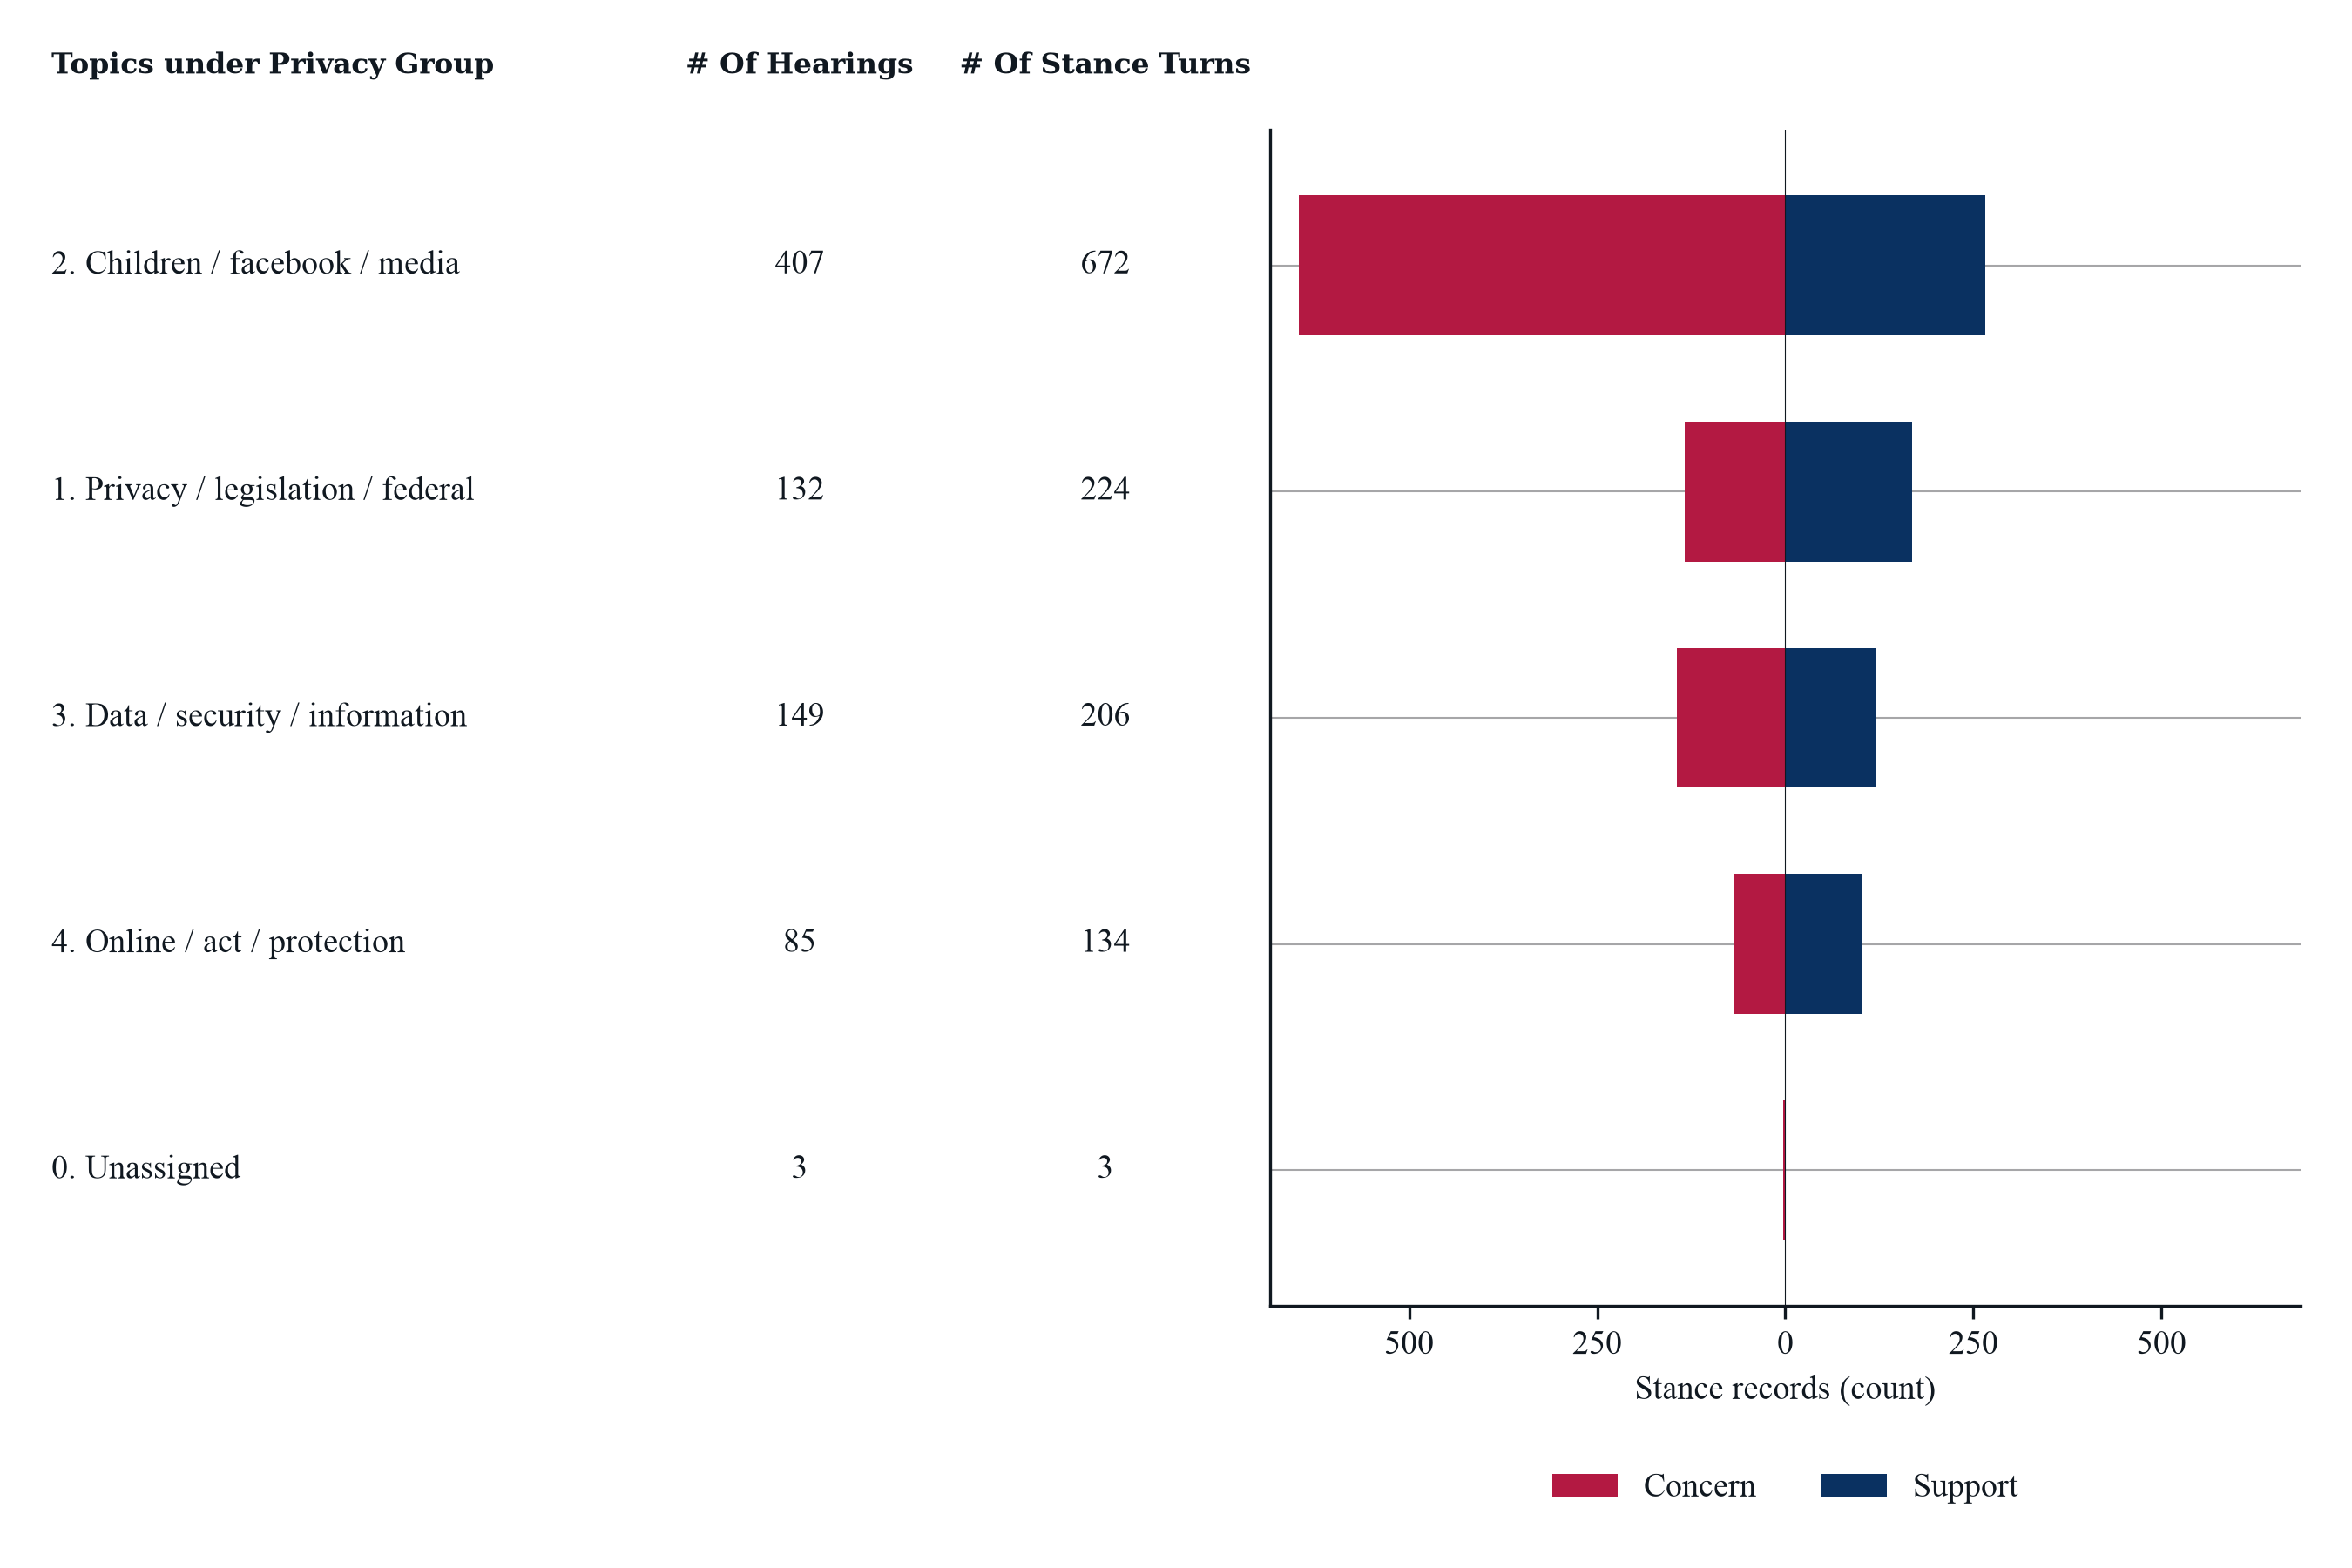

*Notes*: House Science and Senate Commerce, 1999–2025: 1,654 stance records from 1,086 turns and 551 hearings. NMF selects 4 topics by highest mean coherence among 4–12 candidates; exact ties favor fewer. Columns count distinct hearings and turns; bars count stance records. A turn can contribute multiple records or topics. Unassigned: 3 records with no model score. Labels are exploratory; potentially off-topic assignments remain for review. Concern about a harm and support for a remedy can be compatible.

*Source*: Saved stance records; TF–IDF and non-negative matrix factorization (NMF).

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.5/fig_privacy_subtheme_stance


In [16]:
figure_name = "fig_privacy_subtheme_stance"
figure_title = "Figure 2. Concern and Support by Topics under Privacy Group"
figure, axis = plt.subplots()
positions = range(len(summary))
bar_height = 0.62
subtheme_column = MARGIN_INCHES / FIGURE_WIDTH
hearing_column = 0.34
turn_column = 0.47
plot_left = 0.54
plot_right = 1 - MARGIN_INCHES / FIGURE_WIDTH
header_top = 1 - MARGIN_INCHES / FIGURE_HEIGHT
figure.subplots_adjust(left=plot_left, right=plot_right, top=header_top - 0.05, bottom=0.2)

axis.barh(
    positions, -summary["concern_records"], height=bar_height, color=RED, label="Concern"
)
axis.barh(
    positions, summary["support_records"], height=bar_height, color=BLUE, label="Support"
)
axis.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH)
axis.set_yticks(positions)
axis.set_ylim(len(summary) - 0.4, -0.6)
axis.set_xlabel("Stance records (count)")
axis.tick_params(axis="y", left=False, labelleft=False)
axis.spines[["top", "right"]].set_visible(False)

row_transform = blended_transform_factory(figure.transFigure, axis.transData)
for position, row in enumerate(summary.itertuples(index=False)):
    display_label = row.subtheme_label[:1].upper() + row.subtheme_label[1:]
    axis.text(
        subtheme_column, position, textwrap.fill(f"{row.subtheme_id}. {display_label}", width=35), transform=row_transform,
        ha="left", va="center", fontsize=9, clip_on=False,
    )
    axis.text(
        hearing_column, position, f"{row.n_hearings:,}", transform=row_transform,
        ha="center", va="center", fontsize=9, clip_on=False,
    )
    axis.text(
        turn_column, position, f"{row.n_turns:,}", transform=row_transform,
        ha="center", va="center", fontsize=9, clip_on=False,
    )

figure.text(
    subtheme_column, header_top, "Topics under Privacy Group", ha="left", va="top",
    fontsize=8, **BOLD_TEXT,
)
figure.text(
    hearing_column, header_top, "# Of Hearings", ha="center", va="top",
    fontsize=8, **BOLD_TEXT,
)
figure.text(
    turn_column, header_top, "# Of Stance Turns", ha="center", va="top",
    fontsize=8, **BOLD_TEXT,
)

maximum_count = summary[["concern_records", "support_records"]].to_numpy().max()
axis_limit = max(1, maximum_count) * 1.06
axis.set_xlim(-axis_limit, axis_limit)
tick_positions = MaxNLocator(nbins=6, integer=True).tick_values(-axis_limit, axis_limit)
tick_positions = tick_positions[abs(tick_positions) <= axis_limit]
axis.set_xticks(tick_positions, labels=[f"{abs(int(value)):,}" for value in tick_positions])

legend = figure.legend(
    loc="lower center",
    bbox_to_anchor=((plot_left + plot_right) / 2, MARGIN_INCHES / FIGURE_HEIGHT),
    bbox_transform=figure.transFigure, ncol=2, frameon=False, borderaxespad=0,
)
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
legend_top = legend.get_window_extent(renderer).y1
label_bottom = axis.xaxis.label.get_window_extent(renderer).y0
bottom_shift = (legend_top + MARGIN_INCHES * figure.dpi - label_bottom) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)

for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (
    f"House Science and Senate Commerce, 1999–2025: {len(records):,} stance records "
    f"from {len(sample_turns):,} turns and {sample_turns['packageId'].nunique():,} hearings. "
    f"NMF selects {N_SUBTHEMES} topics by highest mean coherence among "
    f"{min(CANDIDATE_SUBTHEMES)}–{max(CANDIDATE_SUBTHEMES)} candidates; exact ties favor fewer. "
    "Columns count distinct hearings and turns; bars count stance records. "
    "A turn can contribute multiple records or topics. "
    f"Unassigned: {(~has_assignment).sum():,} records with no model score. "
    "Labels are exploratory; potentially off-topic assignments remain for review. "
    "Concern about a harm and support for a remedy can be compatible."
)
figure_source = "Saved stance records; TF–IDF and non-negative matrix factorization (NMF)."
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {figure_source}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")

## Step 17. Check the saved outputs

Confirm the selected count follows the fixed rule and all original records survived and the CSV files preserve their text, labels, and counts. Check that the input files are unchanged.

In [17]:
saved_records = pd.read_csv(assignments_file, keep_default_na=False)
saved_summary = pd.read_csv(summary_file, keep_default_na=False)
saved_selection = pd.read_csv(selection_file, float_precision="round_trip")
assert saved_selection["n_subthemes"].tolist() == CANDIDATE_SUBTHEMES
assert saved_selection["selected"].sum() == 1
assert np.isfinite(saved_selection["mean_npmi"]).all()
assert saved_selection["mean_npmi"].between(-1, 1).all()
highest_score = saved_selection["mean_npmi"].max()
winning_count = saved_selection.loc[saved_selection["mean_npmi"].eq(highest_score), "n_subthemes"].min()
assert N_SUBTHEMES == winning_count
assert saved_selection.loc[saved_selection["selected"], "n_subthemes"].item() == N_SUBTHEMES
assert len(subthemes) == model.n_components == N_SUBTHEMES
saved_settings = json.loads(settings_file.read_text())
assert saved_settings["n_subthemes"] == N_SUBTHEMES
assert np.isclose(saved_settings["selection"]["selected_score"], highest_score, rtol=0, atol=1e-12)
assert len(saved_records) == sample_turns["n_stance_records"].sum()
assert not saved_records.duplicated(RECORD_KEYS).any()
assert saved_records["subtheme_id"].between(0, N_SUBTHEMES).all()
assert saved_summary["n_records"].sum() == len(saved_records)
for column in ["topic", "stance", "cited_text", "subtheme_id", "subtheme_label"]:
    assert saved_records[column].tolist() == records[column].tolist(), column
for stance in ["concern", "support"]:
    assert saved_summary[f"{stance}_records"].sum() == saved_records["stance"].eq(stance).sum()
for input_path, expected_hash in input_hashes.items():
    assert hashlib.sha256(Path(input_path).read_bytes()).hexdigest() == expected_hash
print(f"Verified {len(saved_records):,} records and {len(saved_summary)} summary rows.")
print(f"Selected {N_SUBTHEMES} topics by mean NPMI = {highest_score:.6f}.")
print("Next: read privacy_subtheme_model_selection.csv, privacy_subtheme_summary.csv, and privacy_subtheme_examples.csv.")
print("No relevance exclusions were made; these are exploratory topics, not validated categories.")

Verified 1,654 records and 5 summary rows.
Selected 4 topics by mean NPMI = 0.218649.
Next: read privacy_subtheme_model_selection.csv, privacy_subtheme_summary.csv, and privacy_subtheme_examples.csv.
No relevance exclusions were made; these are exploratory topics, not validated categories.
